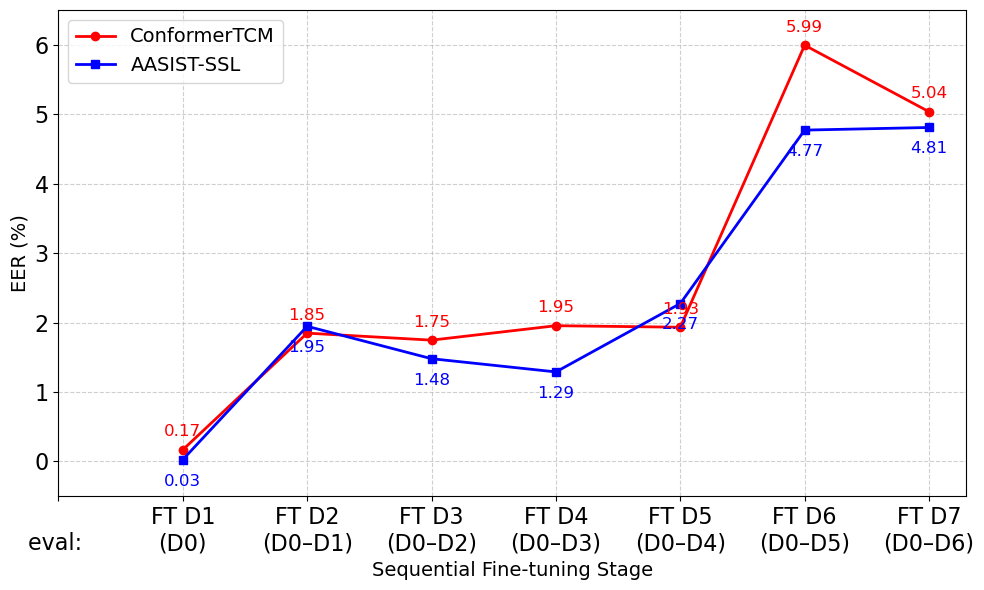

In [1]:
import matplotlib.pyplot as plt

# 수정된 단계 라벨 - eval을 맨 앞에 한 번만
stages = [
    "\neval: ",
    "FT D1\n(D0)",
    "FT D2\n(D0–D1)",
    "FT D3\n(D0–D2)",
    "FT D4\n(D0–D3)",
    "FT D5\n(D0–D4)",
    "FT D6\n(D0–D5)",
    "FT D7\n(D0–D6)",
]

# Diagonal values - eval 라벨 위치에 None 추가
conformer_eer = [None, 0.167, 1.847, 1.746, 1.954, 1.932, 5.993, 5.035]
aasist_eer = [None, 0.0256, 1.9454, 1.4788, 1.2885, 2.273, 4.7706, 4.8083]

plt.figure(figsize=(10, 6))

# 실제 데이터 포인트만 플롯 (첫 번째 "eval:" 라벨은 제외)
data_indices = range(1, len(stages))
plt.plot(data_indices, conformer_eer[1:], marker='o', color='red', linewidth=2, label="ConformerTCM")
plt.plot(data_indices, aasist_eer[1:], marker='s', color='blue', linewidth=2, label="AASIST-SSL")

# 값 라벨 추가 (데이터가 있는 부분만)
for i, v in enumerate(conformer_eer[1:], 1):
    plt.text(i, v+0.15, f"{v:.2f}", ha='center', va='bottom', fontsize=12, color='red', clip_on=True)
for i, v in enumerate(aasist_eer[1:], 1):
    plt.text(i, v-0.2, f"{v:.2f}", ha='center', va='top', fontsize=12, color='blue', clip_on=True)

# X축 설정 - 모든 라벨 사용
plt.xticks(range(len(stages)), stages, fontsize=16)
plt.yticks(fontsize=16)   # y축 tick 글씨 크기 키우기

plt.xlabel("Sequential Fine-tuning Stage", fontsize=14)
plt.ylabel("EER (%)", fontsize=14)

plt.grid(True, linestyle="--", alpha=0.6)
plt.legend(fontsize=14)
plt.ylim(-0.5, 6.5)
plt.tight_layout()
plt.savefig("sequential_ft.pdf", format="pdf", bbox_inches="tight", dpi=400)
plt.show()